# Practical 6: Statistical tests

## Aim
T-test, ANOVA, chi-square test and Pearson correlation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
df = pd.read_csv("TeachingRatings.csv")
alpha = 0.05

In [3]:
def verdict(p, yes, no):
    print("Decision:", yes if p < alpha else no)

1. T-test: gender and evaluation
Male mean 4.0690 (n=268), female mean 3.9010 (n=195)
t = 3.2667, p = 0.0012
Decision: Reject H0, gender affects evaluation


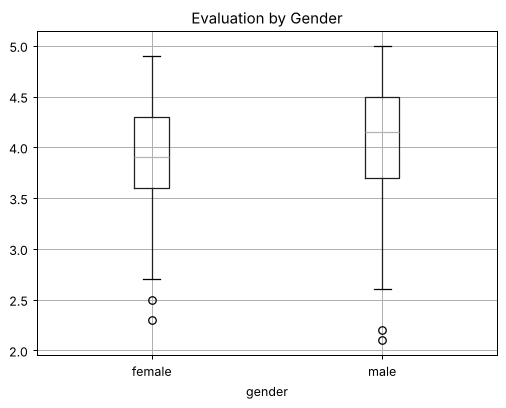

In [4]:
print("1. T-test: gender and evaluation")
men = df.loc[df["gender"] == "male", "eval"]
women = df.loc[df["gender"] == "female", "eval"]
print("Male mean %.4f (n=%d), female mean %.4f (n=%d)" % (men.mean(), len(men), women.mean(), len(women)))
t, p = stats.ttest_ind(men, women, equal_var=False)
print("t = %.4f, p = %.4f" % (t, p))
verdict(p, "Reject H0, gender affects evaluation", "Fail to reject H0")
df.boxplot(column="eval", by="gender")
plt.suptitle("")
plt.title("Evaluation by Gender")
plt.show()


2. ANOVA: beauty and age group
Q1 mean beauty 0.3426 (n=136)
Q2 mean beauty -0.1051 (n=97)
Q3 mean beauty -0.1049 (n=136)
Q4 mean beauty -0.2354 (n=94)
F = 13.7820, p = 0.00000001
Decision: Reject H0, beauty differs by age group


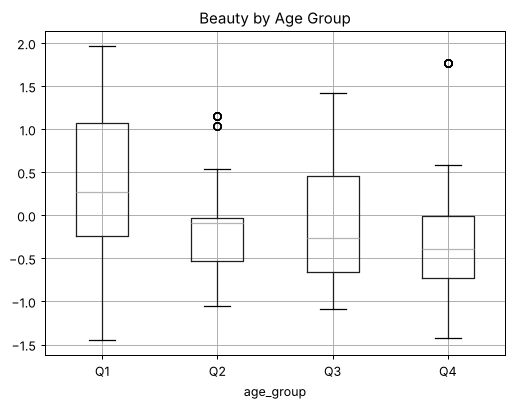

In [5]:
print("\n2. ANOVA: beauty and age group")
df["age_group"] = pd.qcut(df["age"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
parts = [g["beauty"] for _, g in df.groupby("age_group", observed=True)]
for label, g in df.groupby("age_group", observed=True):
    print("%s mean beauty %.4f (n=%d)" % (label, g["beauty"].mean(), len(g)))
f, p = stats.f_oneway(*parts)
print("F = %.4f, p = %.8f" % (f, p))
verdict(p, "Reject H0, beauty differs by age group", "Fail to reject H0")
df.boxplot(column="beauty", by="age_group")
plt.suptitle("")
plt.title("Beauty by Age Group")
plt.show()


3. Chi-square: gender and tenure
tenure  no  yes
gender         
female  50  145
male    52  216
chi2 = 2.2068, dof = 1, p = 0.1374
Decision: Fail to reject H0, no association


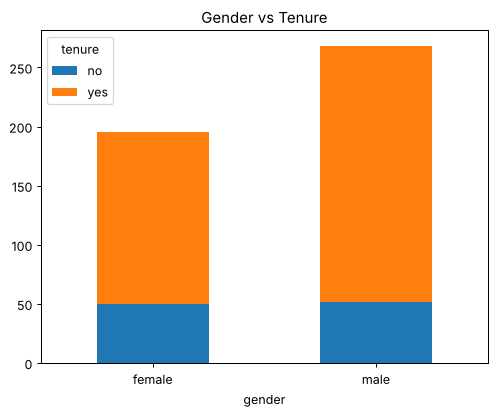

In [6]:
print("\n3. Chi-square: gender and tenure")
table = pd.crosstab(df["gender"], df["tenure"])
print(table)
chi, p, dof, _ = stats.chi2_contingency(table)
print("chi2 = %.4f, dof = %d, p = %.4f" % (chi, dof, p))
verdict(p, "Reject H0, gender and tenure are associated", "Fail to reject H0, no association")
table.plot(kind="bar", stacked=True, rot=0)
plt.title("Gender vs Tenure")
plt.show()


4. Correlation: beauty and evaluation
r = 0.1890, p = 0.00004247
Decision: Reject H0, significant positive correlation


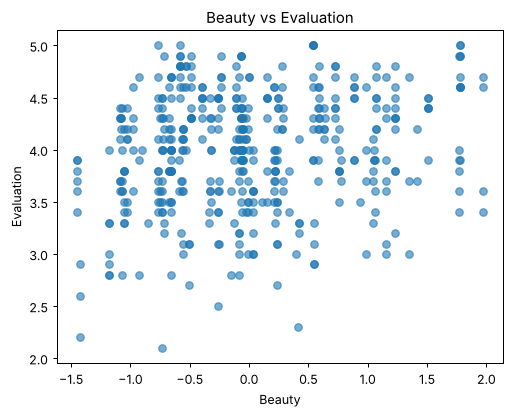

In [7]:
print("\n4. Correlation: beauty and evaluation")
r, p = stats.pearsonr(df["eval"], df["beauty"])
print("r = %.4f, p = %.8f" % (r, p))
verdict(p, "Reject H0, significant positive correlation", "Fail to reject H0")
plt.scatter(df["beauty"], df["eval"], alpha=0.6)
plt.title("Beauty vs Evaluation")
plt.xlabel("Beauty")
plt.ylabel("Evaluation")
plt.show()

In [8]:
print("\nResult: gender, age group and beauty each show a significant effect;")
print("gender and tenure are not significantly associated.")


Result: gender, age group and beauty each show a significant effect;
gender and tenure are not significantly associated.
